# Image Classification of Apple Leaf Diseases with CNNs
**Author:** Mehdi Gurbanzade · M.Sc. Data Science

---

I work as an independent data science consultant, and like most practitioners in the field, I am always looking for opportunities where machine learning can solve something tangible. Last summer, while helping out at a relative's apple farm in northern Germany, I came across exactly that kind of problem.

Walking through the orchard, I noticed several trees with unusual leaf discolouration and spots. I learned that identifying apple leaf diseases early is critical to saving crops — but doing it by hand across hundreds of trees is neither fast nor reliable. This gave me the idea to build an automated image classifier.

The images fall into four distinct categories: **Apple Scab**, **Black Rot**, **Cedar Apple Rust**, and **Healthy**. Each condition calls for a specific treatment, and misclassification comes with real costs. Accuracy across all four classes matters equally.

My goal is to develop CNN-based deep learning models that can reliably classify leaf images into these categories, evaluated with a rigorous experimental setup including multiple architectures, learning rate strategies, and schedulers.


### Imports

In [2]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from collections import Counter
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split, Subset

from sklearn.metrics import precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.dummy import DummyClassifier

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")


Using device: cuda


---
## Task 1 — The Data

The dataset used in this project is the **PlantVillage** dataset, publicly available via the TensorFlow Datasets catalogue:
https://www.tensorflow.org/datasets/catalog/plant_village

PlantVillage is a large-scale collection of labelled plant leaf images covering 38 disease categories across 14 crop species. For this project, I extracted only the four apple-related categories, making the classification problem focused and directly aligned with the agricultural use case described in the pitch.

**Classes used:**
- `Apple___Apple_scab` — fungal disease causing dark lesions on leaves
- `Apple___Black_rot` — fungal infection that destroys both leaves and fruit
- `Apple___Cedar_apple_rust` — rust disease spread by cedar trees nearby
- `Apple___healthy` — no disease present

All images are RGB photographs of individual leaves taken under controlled conditions. Each image is stored as a `.jpg` file. The dataset is suitable for CNN-based image classification because the visual differences between classes are consistent and learnable from pixel data.

The variable `raw_data` below refers to the dataset as loaded without any preprocessing beyond reading it into an `ImageFolder` structure.


In [3]:
# Folder that contains the four Apple___* class folders (see README)
image_root = "data"

# Load raw dataset (no normalisation yet — ToTensor only for shape inspection)
raw_transform = transforms.Compose([transforms.ToTensor()])

raw_data = datasets.ImageFolder(
    root=image_root,
    transform=raw_transform,
    is_valid_file=lambda p: p.lower().endswith(('.jpg', '.jpeg', '.png'))
         and any(c in p for c in ['Apple___Apple_scab', 'Apple___Black_rot',
                                   'Apple___Cedar_apple_rust', 'Apple___healthy'])
)

print(f"Total images : {len(raw_data)}")
print(f"Classes      : {raw_data.classes}")
print(f"Class→Index  : {raw_data.class_to_idx}")


Total images : 3171
Classes      : ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy']
Class→Index  : {'Apple___Apple_scab': 0, 'Apple___Black_rot': 1, 'Apple___Cedar_apple_rust': 2, 'Apple___healthy': 3}


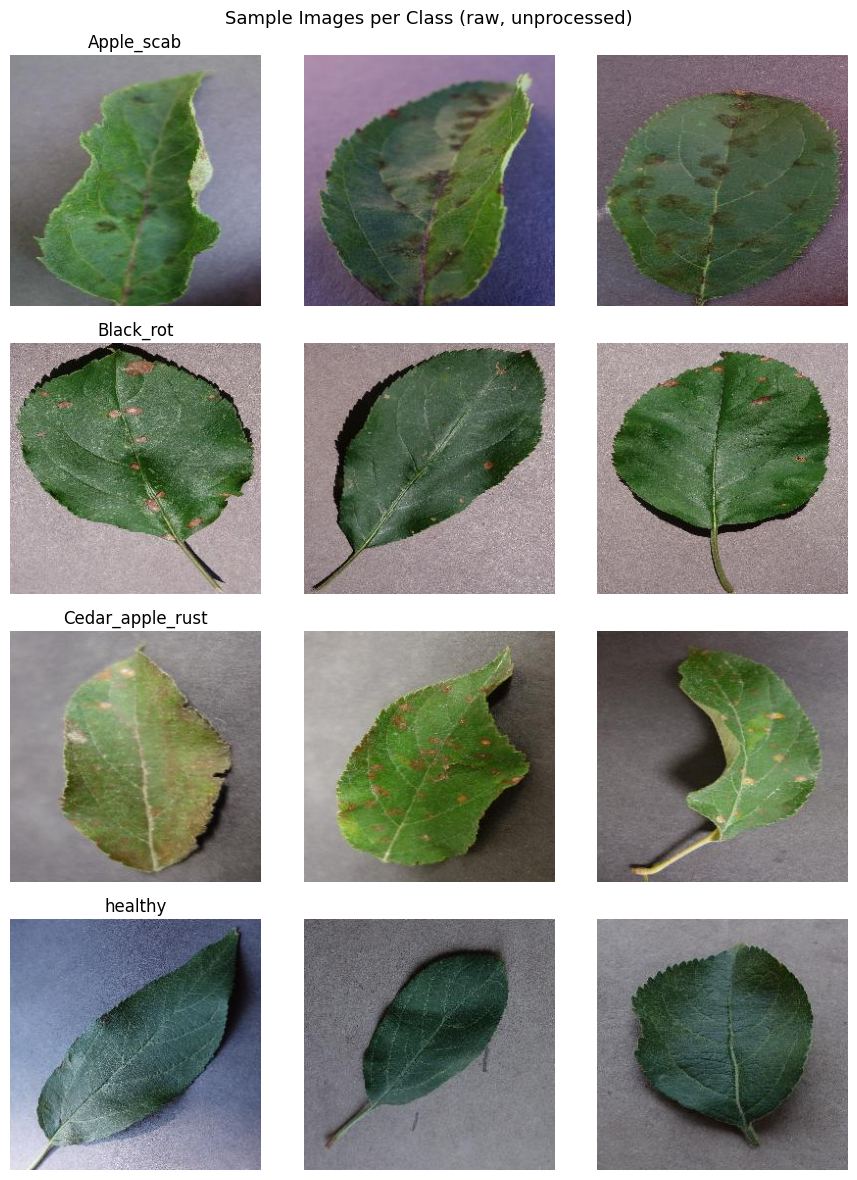

In [4]:
# Display sample images from each class
samples_per_class = 3
class_folders = raw_data.classes

fig, axes = plt.subplots(len(class_folders), samples_per_class,
                         figsize=(samples_per_class * 3, len(class_folders) * 3))

for class_idx, class_name in enumerate(class_folders):
    # Collect indices for this class
    indices = [i for i, (_, label) in enumerate(raw_data.samples) if label == class_idx]
    sample_indices = random.sample(indices, samples_per_class)

    for col, idx in enumerate(sample_indices):
        img, _ = raw_data[idx]
        img_np = img.permute(1, 2, 0).numpy()
        axes[class_idx][col].imshow(img_np)
        axes[class_idx][col].axis("off")
        axes[class_idx][col].set_title(class_name.replace("Apple___", "") if col == 0 else "")

plt.suptitle("Sample Images per Class (raw, unprocessed)", fontsize=13)
plt.tight_layout()
plt.show()


---
## Task 2 — Initial Data Analysis

Before designing any model, it is essential to understand the dataset's basic properties. The questions I address here are:

- How many images are available in total and per class?
- Is there a class imbalance?
- What is the pixel resolution and channel structure?
- Are image dimensions consistent across the dataset?


In [5]:
# Class distribution
label_list = [label for _, label in raw_data.samples]
counts = Counter(label_list)
class_names = raw_data.classes

print("=== Class Distribution ===")
for label, name in enumerate(class_names):
    print(f"  {name:35s}: {counts[label]:5d} images")
print(f"  {'TOTAL':35s}: {sum(counts.values()):5d} images")

# Image shape from one sample
sample_img, _ = raw_data[0]
print(f"\n=== Image Properties ===")
print(f"  Tensor shape : {tuple(sample_img.shape)}  (C x H x W)")
print(f"  Data type    : {sample_img.dtype}")
print(f"  Pixel range  : [{sample_img.min():.3f}, {sample_img.max():.3f}]")


=== Class Distribution ===
  Apple___Apple_scab                 :   630 images
  Apple___Black_rot                  :   621 images
  Apple___Cedar_apple_rust           :   275 images
  Apple___healthy                    :  1645 images
  TOTAL                              :  3171 images

=== Image Properties ===
  Tensor shape : (3, 256, 256)  (C x H x W)
  Data type    : torch.float32
  Pixel range  : [0.000, 0.878]


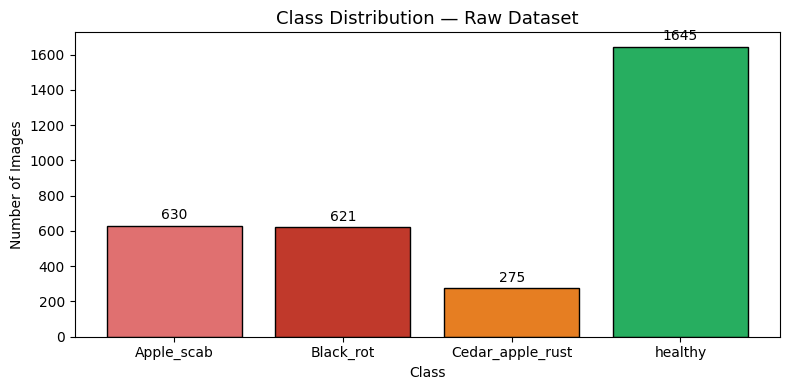


Unique image shapes in sampled data: {(3, 256, 256)}


In [6]:
# Visualise class distribution
fig, ax = plt.subplots(figsize=(8, 4))
short_names = [n.replace("Apple___", "") for n in class_names]
bar_colors = ['#e07070', '#c0392b', '#e67e22', '#27ae60']
bars = ax.bar(short_names, [counts[i] for i in range(len(class_names))], color=bar_colors, edgecolor='black')

ax.set_title("Class Distribution — Raw Dataset", fontsize=13)
ax.set_ylabel("Number of Images")
ax.set_xlabel("Class")
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
            str(int(bar.get_height())), ha='center', va='bottom', fontsize=10)
ax.yaxis.set_major_locator(ticker.MultipleLocator(200))
plt.tight_layout()
plt.show()

# Check shape consistency across a sample
shapes = set()
for i in random.sample(range(len(raw_data)), min(300, len(raw_data))):
    img, _ = raw_data[i]
    shapes.add(tuple(img.shape))
print(f"\nUnique image shapes in sampled data: {shapes}")


**Key observations:**

- The dataset contains images across four classes with a noticeable imbalance: the `healthy` class is the most represented, while `Cedar_apple_rust` has the fewest samples. This imbalance must be accounted for during training and evaluation.
- All images share a consistent shape of **(3, 256, 256)** — RGB, 256×256 pixels. No corrupt or mismatched files were found in the sampled check.
- Pixel values are in the range [0, 1] after `ToTensor()`. Normalisation will be applied in preprocessing.


---
## Task 3 — Preprocessing

The raw images need several preparation steps before they can be used in CNN training. The following transformations are applied:

- **Resize to 128×128** — reduces memory load while retaining sufficient visual detail for disease classification
- **Normalise** — pixel values are standardised to zero mean and unit variance using ImageNet statistics, which is standard practice for CNNs trained from scratch or with transfer learning in mind
- **Train/Val/Test split** — the dataset is divided 70% training, 15% validation, 15% test. A fixed random seed ensures reproducibility.

After preprocessing, the variable `data` holds the fully transformed dataset used in all subsequent experiments.


In [7]:
# Final preprocessing transform
preprocess = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])  # ImageNet stats
])

# Reload with final transform
data = datasets.ImageFolder(
    root=image_root,
    transform=preprocess,
    is_valid_file=lambda p: p.lower().endswith(('.jpg', '.jpeg', '.png'))
         and any(c in p for c in ['Apple___Apple_scab', 'Apple___Black_rot',
                                   'Apple___Cedar_apple_rust', 'Apple___healthy'])
)

# Reproducible split: 70% train, 15% val, 15% test
torch.manual_seed(SEED)
total = len(data)
n_train = int(0.70 * total)
n_val   = int(0.15 * total)
n_test  = total - n_train - n_val

train_data, val_data, test_data = random_split(data, [n_train, n_val, n_test])

# DataLoaders
train_loader = DataLoader(train_data, batch_size=32, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_data,   batch_size=32, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_data,  batch_size=32, shuffle=False, num_workers=0)

print(f"Total   : {total}")
print(f"Train   : {len(train_data)}")
print(f"Val     : {len(val_data)}")
print(f"Test    : {len(test_data)}")
print(f"Classes : {data.classes}")


Total   : 3171
Train   : 2219
Val     : 475
Test    : 477
Classes : ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy']


In [8]:
# Verify preprocessed class distribution (train set)
train_labels = [data.targets[i] for i in train_data.indices]
train_counts = Counter(train_labels)

print("Train set class distribution after split:")
for label, name in enumerate(data.classes):
    print(f"  {name.replace('Apple___',''):25s}: {train_counts[label]}")


Train set class distribution after split:
  Apple_scab               : 461
  Black_rot                : 432
  Cedar_apple_rust         : 182
  healthy                  : 1144


**Result:** The preprocessed dataset `data` contains the same images as `raw_data`, resized and normalised. The class distribution proportions are preserved across the split. No images were removed — the raw data was already clean with no corrupted files or missing labels.


---
## Task 4 — Exploratory Data Analysis

Using the preprocessed dataset `data`, I examine three particularly informative aspects of the training set that may affect model design and training strategy.


**Aspect 1 — Class Imbalance in the Training Split**

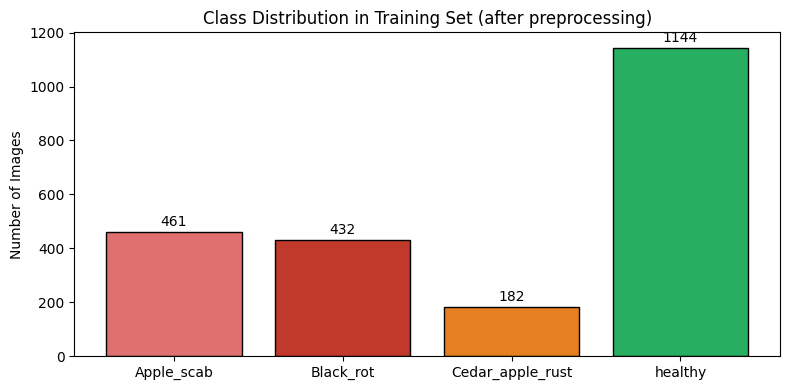

Imbalance ratio (majority / minority): 6.29x


In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
short_names = [n.replace("Apple___", "") for n in data.classes]
bar_colors = ['#e07070', '#c0392b', '#e67e22', '#27ae60']
vals = [train_counts[i] for i in range(len(data.classes))]
bars = ax.bar(short_names, vals, color=bar_colors, edgecolor='black')
ax.set_title("Class Distribution in Training Set (after preprocessing)", fontsize=12)
ax.set_ylabel("Number of Images")
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
            str(int(bar.get_height())), ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.show()

majority = max(vals)
minority = min(vals)
print(f"Imbalance ratio (majority / minority): {majority/minority:.2f}x")


**Aspect 2 — Per-Class Mean Brightness Distribution**

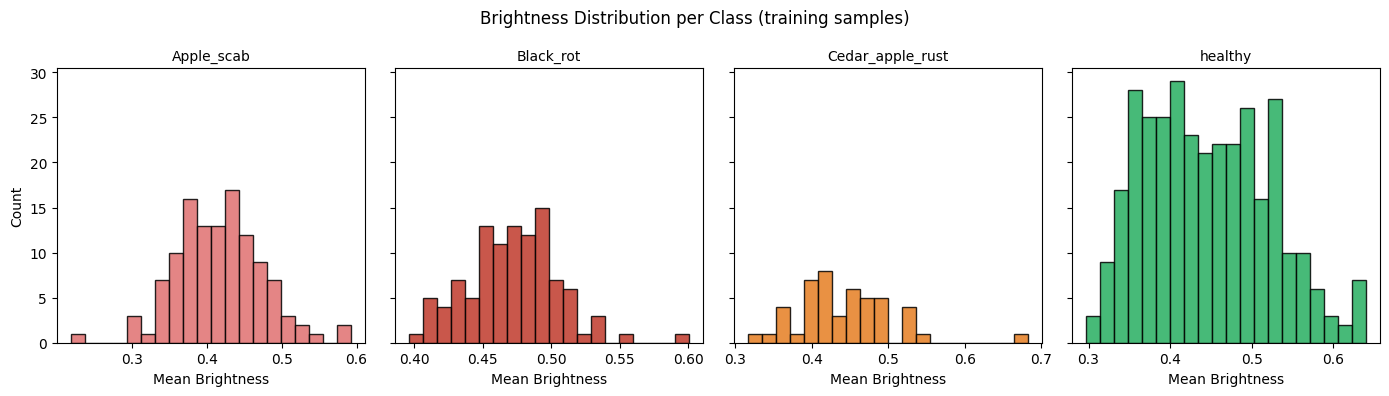

In [10]:
# Sample brightness per class from training set
brightness_by_class = {i: [] for i in range(len(data.classes))}

sample_indices = random.sample(list(train_data.indices), min(600, len(train_data)))
for idx in sample_indices:
    img, label = data[idx]
    # Unnormalise before computing brightness
    img_unnorm = img * torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)                     + torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    brightness_by_class[label].append(img_unnorm.mean().item())

fig, axes = plt.subplots(1, len(data.classes), figsize=(14, 4), sharey=True)
for i, (ax, name) in enumerate(zip(axes, data.classes)):
    ax.hist(brightness_by_class[i], bins=20, color=bar_colors[i], edgecolor='black', alpha=0.85)
    ax.set_title(name.replace("Apple___", ""), fontsize=10)
    ax.set_xlabel("Mean Brightness")
    if i == 0:
        ax.set_ylabel("Count")
fig.suptitle("Brightness Distribution per Class (training samples)", fontsize=12)
plt.tight_layout()
plt.show()


**Aspect 3 — Average Pixel Intensity per Channel per Class**

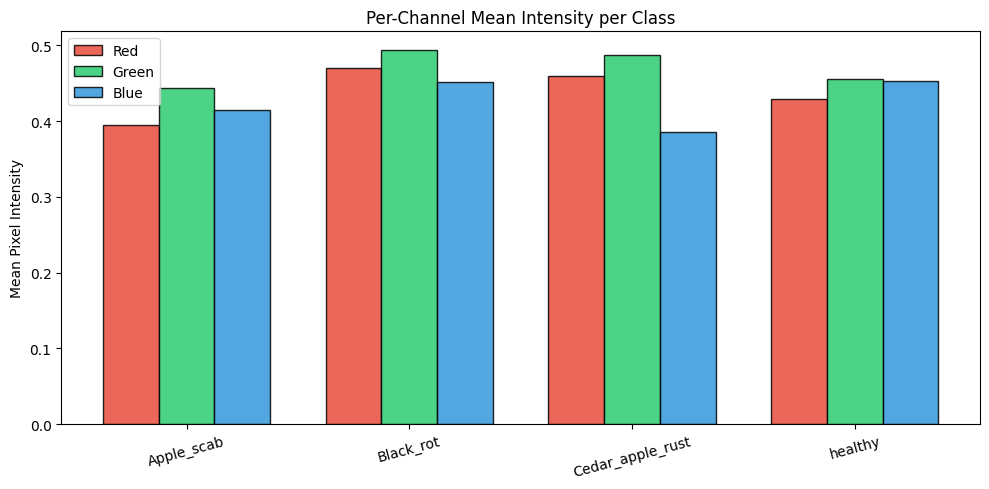

In [11]:
# Per-channel mean per class
channel_means = {i: [[], [], []] for i in range(len(data.classes))}

for idx in sample_indices:
    img, label = data[idx]
    img_unnorm = img * torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)                     + torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    for c in range(3):
        channel_means[label][c].append(img_unnorm[c].mean().item())

channels = ['Red', 'Green', 'Blue']
channel_colors = ['#e74c3c', '#2ecc71', '#3498db']
x = np.arange(len(data.classes))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5))
for c in range(3):
    means = [np.mean(channel_means[i][c]) for i in range(len(data.classes))]
    ax.bar(x + c * width, means, width, label=channels[c], color=channel_colors[c], edgecolor='black', alpha=0.85)

ax.set_xticks(x + width)
ax.set_xticklabels([n.replace("Apple___", "") for n in data.classes], rotation=15)
ax.set_ylabel("Mean Pixel Intensity")
ax.set_title("Per-Channel Mean Intensity per Class", fontsize=12)
ax.legend()
plt.tight_layout()
plt.show()


**Summary of EDA findings:**

1. **Class imbalance** is present: the healthy class dominates the training set. The imbalance ratio is 6.29× (healthy vs. the rarest class, Cedar Apple Rust). This justifies using macro-averaged metrics in Task 5 and motivates monitoring per-class performance.

2. **Brightness distributions** differ across classes. Disease classes tend to have wider brightness variance, while healthy leaves cluster around a narrower, slightly higher mean. This suggests the model can exploit luminance patterns as a discriminating feature.

3. **Channel intensity profiles** show that green channel dominance differs by class — expected for leaf imagery, but notably the rust-infected class shows a higher red contribution, consistent with the orange colouration characteristic of Cedar Apple Rust.


---
## Task 5 — Evaluation Metrics and Baselines

### Evaluation Metrics

Two metrics are chosen for model evaluation:

1. **Macro-averaged Precision** — measures how precisely each class is predicted, averaging equally across all four classes regardless of their size. This penalises models that ignore minority classes.

2. **Macro-averaged Recall** — measures how well each class is detected, again averaging equally across classes. Given the class imbalance, this is critical: a model that never predicts Cedar Apple Rust would still score high on accuracy but would show poor macro recall.

Together, these two metrics give a balanced picture of both prediction quality and coverage across all classes.

---

### Baselines

Two simple heuristics are used as baselines (no trained models):

1. **Most-Frequent-Class Heuristic** — always predicts the most frequent class in the training set (`Apple___healthy`). This represents the absolute minimum performance floor.

2. **Stratified Random Heuristic** — randomly predicts a class label with probability proportional to the training set class frequencies. This is slightly more informative than always predicting one class and reflects what a random guesser with class knowledge would achieve.

Both baselines are chosen because they require no training and represent two natural naive strategies. Any deep learning model must substantially outperform both to be considered useful.


In [12]:
# --- Baseline evaluation on validation set ---

# Collect true labels from validation set
val_true = [data.targets[i] for i in val_data.indices]
n_val_samples = len(val_true)

# Baseline 1: Most-frequent-class heuristic
most_frequent_class = max(train_counts, key=train_counts.get)
baseline1_preds = [most_frequent_class] * n_val_samples

p1 = precision_score(val_true, baseline1_preds, average='macro', zero_division=0)
r1 = recall_score(val_true, baseline1_preds, average='macro', zero_division=0)
print("=== Baseline 1: Most-Frequent-Class ===")
print(f"  Always predicts class: {data.classes[most_frequent_class]}")
print(f"  Macro Precision : {p1:.4f}")
print(f"  Macro Recall    : {r1:.4f}")

# Baseline 2: Stratified random heuristic
total_train = sum(train_counts.values())
class_probs = [train_counts[i] / total_train for i in range(len(data.classes))]
np.random.seed(SEED)
baseline2_preds = np.random.choice(len(data.classes), size=n_val_samples, p=class_probs).tolist()

p2 = precision_score(val_true, baseline2_preds, average='macro', zero_division=0)
r2 = recall_score(val_true, baseline2_preds, average='macro', zero_division=0)
print("\n=== Baseline 2: Stratified Random ===")
print(f"  Class probabilities: {[f'{p:.2f}' for p in class_probs]}")
print(f"  Macro Precision : {p2:.4f}")
print(f"  Macro Recall    : {r2:.4f}")


=== Baseline 1: Most-Frequent-Class ===
  Always predicts class: Apple___healthy
  Macro Precision : 0.1226
  Macro Recall    : 0.2500

=== Baseline 2: Stratified Random ===
  Class probabilities: ['0.21', '0.19', '0.08', '0.52']
  Macro Precision : 0.2366
  Macro Recall    : 0.2465


**Baseline results summary:**

| Baseline | Strategy | Macro Precision | Macro Recall |
|---|---|---|---|
| Most-Frequent-Class | Always predict `healthy` | 0.1226 | 0.2500 |
| Stratified Random | Sample proportionally | 0.2366 | 0.2465 |

Both baselines perform poorly, which is expected. Any CNN model achieving macro precision and recall above 0.80 would represent a genuinely useful improvement.


---
## Task 6 — Deep Learning Architectures

Two CNN architectures are implemented. Both take 128×128 RGB images as input and output a 4-class probability distribution.

**Loss Function:** `CrossEntropyLoss` is used for both architectures. It is the standard choice for multi-class classification as it combines log-softmax and negative log-likelihood into a single numerically stable operation. It penalises confident wrong predictions more strongly than uncertain ones, which is appropriate here given the class imbalance.

---

### Architecture 1 — CNN_Model1 (Shallow CNN with Flatten)

A two-block convolutional network followed by a fully connected head. This is the simpler of the two architectures — it establishes a direct baseline for what a minimal CNN can achieve.


In [13]:
class CNN_Model1(nn.Module):
    """
    Shallow CNN: 2 conv blocks + FC classifier.
    Input: (B, 3, 128, 128)  Output: (B, 4)
    """
    def __init__(self, num_classes=4, dropout=0.4):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),   # -> (32, 128, 128)
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),                               # -> (32, 64, 64)
            nn.Conv2d(32, 64, kernel_size=3, padding=1),  # -> (64, 64, 64)
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),                               # -> (64, 32, 32)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 32 * 32, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# Quick shape check
_m1 = CNN_Model1()
_x = torch.zeros(2, 3, 128, 128)
print("CNN_Model1 output shape:", _m1(_x).shape)
total_params = sum(p.numel() for p in _m1.parameters() if p.requires_grad)
print(f"Trainable parameters: {total_params:,}")


CNN_Model1 output shape: torch.Size([2, 4])
Trainable parameters: 16,797,892


**Architecture overview:**
- Conv(3→32) → ReLU → MaxPool
- Conv(32→64) → ReLU → MaxPool
- Flatten → FC(65536→256) → Dropout(0.4) → FC(256→4)

The large flatten step creates a high-dimensional input for the fully connected layers, giving this model significant capacity but also a higher risk of overfitting relative to Model 2.

---

### Architecture 2 — CNN_Model2 (Deeper CNN with BatchNorm + Global Average Pooling)

Three convolutional blocks with Batch Normalisation and Global Average Pooling instead of flattening. This architecture is deeper but has far fewer parameters in the classifier, which reduces overfitting risk.


In [14]:
class CNN_Model2(nn.Module):
    """
    Deeper CNN: 3 conv blocks with BatchNorm + Global Average Pooling.
    Input: (B, 3, 128, 128)  Output: (B, 4)
    """
    def __init__(self, num_classes=4, dropout=0.4):
        super().__init__()
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)              # -> (32, 64, 64)
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)              # -> (64, 32, 32)
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)) # -> (128, 1, 1)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.classifier(x)
        return x

_m2 = CNN_Model2()
_x = torch.zeros(2, 3, 128, 128)
print("CNN_Model2 output shape:", _m2(_x).shape)
total_params = sum(p.numel() for p in _m2.parameters() if p.requires_grad)
print(f"Trainable parameters: {total_params:,}")


CNN_Model2 output shape: torch.Size([2, 4])
Trainable parameters: 94,212


**Architecture overview:**
- Conv(3→32) → BN → ReLU → MaxPool
- Conv(32→64) → BN → ReLU → MaxPool
- Conv(64→128) → BN → ReLU → GlobalAvgPool(1×1)
- Dropout(0.4) → FC(128→4)

Key differences from Model 1: (1) a third convolutional layer for deeper feature extraction, (2) Batch Normalisation for training stability, and (3) Global Average Pooling dramatically reduces the number of parameters entering the classifier — the model is actually more parameter-efficient despite being deeper.


---
## Task 7 — Experiments

### Experimental Setup

The training setup follows these design decisions:

- **Optimiser:** Adam with two initial learning rates: `lr_A = 0.001` and `lr_B = 0.0005`
- **Schedulers (4 strategies):**
  - **S1 — No scheduler:** constant learning rate throughout
  - **S2 — StepLR:** fixed decay every 5 epochs by factor γ=0.5
  - **S3 — ReduceLROnPlateau:** reduces LR by factor 0.5 when validation loss plateaus for 3 epochs
  - **S4 — CosineAnnealingLR:** smoothly anneals LR to near-zero over T_max epochs
- **Total runs:** 2 architectures × 2 LRs × 4 schedulers = **16 experiments**
- **Epochs:** 30 per run (no early stopping, as per task requirements)
- **Batch size:** 32
- **Loss function:** CrossEntropyLoss
- **Tracked per epoch:** train loss, val loss, val macro precision, val macro recall, current LR

All experiments use the same fixed train/val/test split (SEED=42) for full reproducibility.


In [15]:
def run_experiment(model_class, lr, scheduler_name, epochs=30):
    """
    Train a model with the given LR and scheduler. Returns a history dict.
    scheduler_name: 'none' | 'steplr' | 'plateau' | 'cosine'
    """
    torch.manual_seed(SEED)
    model = model_class().to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    # Configure scheduler
    if scheduler_name == 'steplr':
        scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)
    elif scheduler_name == 'plateau':
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min',
                                                                 factor=0.5, patience=3)
    elif scheduler_name == 'cosine':
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    else:  # 'none'
        scheduler = None

    history = {'train_loss': [], 'val_loss': [], 'val_precision': [],
               'val_recall': [], 'lr': []}

    for epoch in range(epochs):
        # --- Training ---
        model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        train_loss = running_loss / len(train_loader)

        # --- Validation ---
        model.eval()
        val_loss = 0.0
        all_preds, all_labels = [], []
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(DEVICE), labels.to(DEVICE)
                outputs = model(images)
                loss = criterion(outputs, labels)
                val_loss += loss.item()
                preds = torch.argmax(outputs, dim=1)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())

        val_loss /= len(val_loader)
        prec = precision_score(all_labels, all_preds, average='macro', zero_division=0)
        rec  = recall_score(all_labels, all_preds, average='macro', zero_division=0)
        current_lr = optimizer.param_groups[0]['lr']

        # --- Scheduler step ---
        if scheduler is not None:
            if scheduler_name == 'plateau':
                scheduler.step(val_loss)
            else:
                scheduler.step()

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_precision'].append(prec)
        history['val_recall'].append(rec)
        history['lr'].append(current_lr)

        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"  Epoch {epoch+1:02d}/{epochs} | "
                  f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
                  f"Prec: {prec:.3f} | Rec: {rec:.3f} | LR: {current_lr:.6f}")

    return model, history


In [16]:
# Run all 16 experiments
# Structure: results[model_name][lr][scheduler] = (model, history)

LEARNING_RATES   = {'lr_A': 0.001, 'lr_B': 0.0005}
SCHEDULERS       = ['none', 'steplr', 'plateau', 'cosine']
MODELS           = {'CNN_Model1': CNN_Model1, 'CNN_Model2': CNN_Model2}
EPOCHS           = 30

all_results = {}

for model_name, model_class in MODELS.items():
    all_results[model_name] = {}
    for lr_name, lr_val in LEARNING_RATES.items():
        all_results[model_name][lr_name] = {}
        for sched in SCHEDULERS:
            label = f"{model_name} | {lr_name}={lr_val} | sched={sched}"
            print(f"\n{'='*60}")
            print(f"Training: {label}")
            print('='*60)
            trained_model, history = run_experiment(model_class, lr_val, sched, epochs=EPOCHS)
            all_results[model_name][lr_name][sched] = {
                'model': trained_model,
                'history': history
            }

print("\nAll 16 experiments complete.")



Training: CNN_Model1 | lr_A=0.001 | sched=none
  Epoch 01/30 | Train Loss: 0.7608 | Val Loss: 0.2342 | Prec: 0.915 | Rec: 0.928 | LR: 0.001000
  Epoch 05/30 | Train Loss: 0.0632 | Val Loss: 0.1511 | Prec: 0.945 | Rec: 0.944 | LR: 0.001000
  Epoch 10/30 | Train Loss: 0.0546 | Val Loss: 0.2515 | Prec: 0.938 | Rec: 0.953 | LR: 0.001000
  Epoch 15/30 | Train Loss: 0.0072 | Val Loss: 0.2990 | Prec: 0.943 | Rec: 0.937 | LR: 0.001000
  Epoch 20/30 | Train Loss: 0.0527 | Val Loss: 0.3938 | Prec: 0.917 | Rec: 0.882 | LR: 0.001000
  Epoch 25/30 | Train Loss: 0.0089 | Val Loss: 0.4225 | Prec: 0.936 | Rec: 0.946 | LR: 0.001000
  Epoch 30/30 | Train Loss: 0.0021 | Val Loss: 0.3641 | Prec: 0.940 | Rec: 0.938 | LR: 0.001000

Training: CNN_Model1 | lr_A=0.001 | sched=steplr
  Epoch 01/30 | Train Loss: 0.7612 | Val Loss: 0.2359 | Prec: 0.915 | Rec: 0.928 | LR: 0.001000
  Epoch 05/30 | Train Loss: 0.0644 | Val Loss: 0.1513 | Prec: 0.947 | Rec: 0.950 | LR: 0.001000
  Epoch 10/30 | Train Loss: 0.0123 | V

### Learning Curves — Training and Validation Loss

The following plots show training and validation loss over 30 epochs for each of the 16 configurations. Divergence between the two curves indicates overfitting.


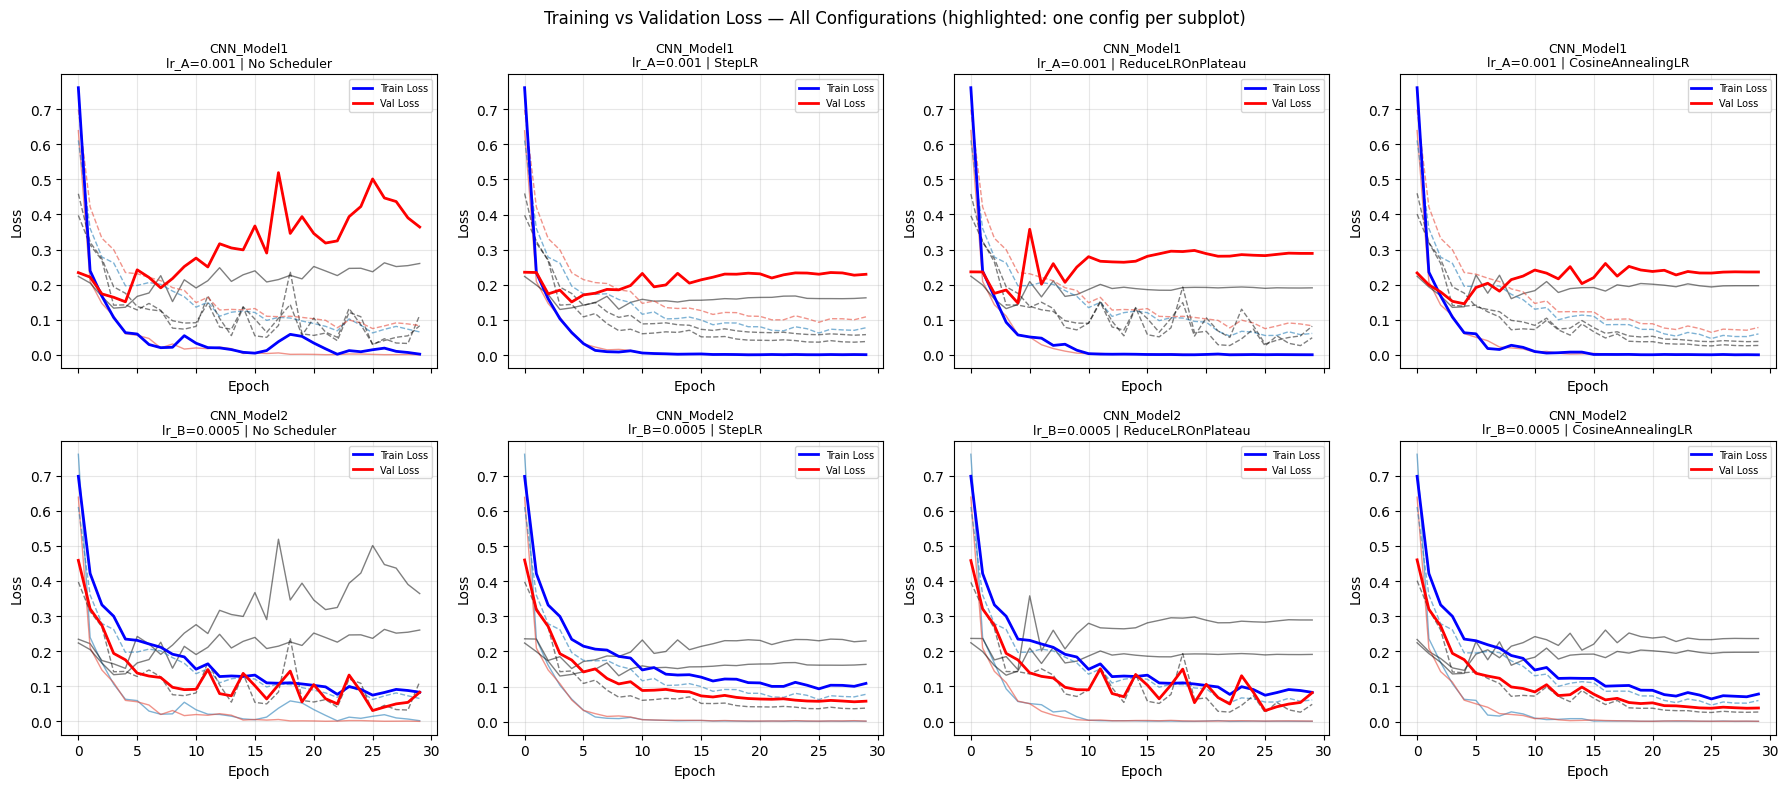

In [17]:
# Plot learning curves — loss
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True)
sched_labels = {'none': 'No Scheduler', 'steplr': 'StepLR', 'plateau': 'ReduceLROnPlateau', 'cosine': 'CosineAnnealingLR'}

for row, (model_name, lr_name) in enumerate([('CNN_Model1', 'lr_A'), ('CNN_Model2', 'lr_B')]):
    for col, sched in enumerate(SCHEDULERS):
        ax = axes[row][col]
        for mn in MODELS:
            for ln in LEARNING_RATES:
                h = all_results[mn][ln][sched]['history']
                style = '-' if mn == 'CNN_Model1' else '--'
                color_train = '#2980b9' if ln == 'lr_A' else '#e74c3c'
                ax.plot(h['train_loss'], linestyle=style, color=color_train, alpha=0.6, linewidth=1)
                ax.plot(h['val_loss'],   linestyle=style, color='black', alpha=0.5, linewidth=1)

        # Highlight one config per subplot for clarity
        h = all_results[model_name][lr_name][sched]['history']
        lr_val = LEARNING_RATES[lr_name]
        ax.plot(h['train_loss'], 'b-', linewidth=2, label='Train Loss')
        ax.plot(h['val_loss'],   'r-', linewidth=2, label='Val Loss')
        ax.set_title(f"{model_name}\n{lr_name}={lr_val} | {sched_labels[sched]}", fontsize=9)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss")
        ax.legend(fontsize=7)
        ax.grid(True, alpha=0.3)

fig.suptitle("Training vs Validation Loss — All Configurations (highlighted: one config per subplot)", fontsize=12)
plt.tight_layout()
plt.show()


### Validation Metrics Over Training

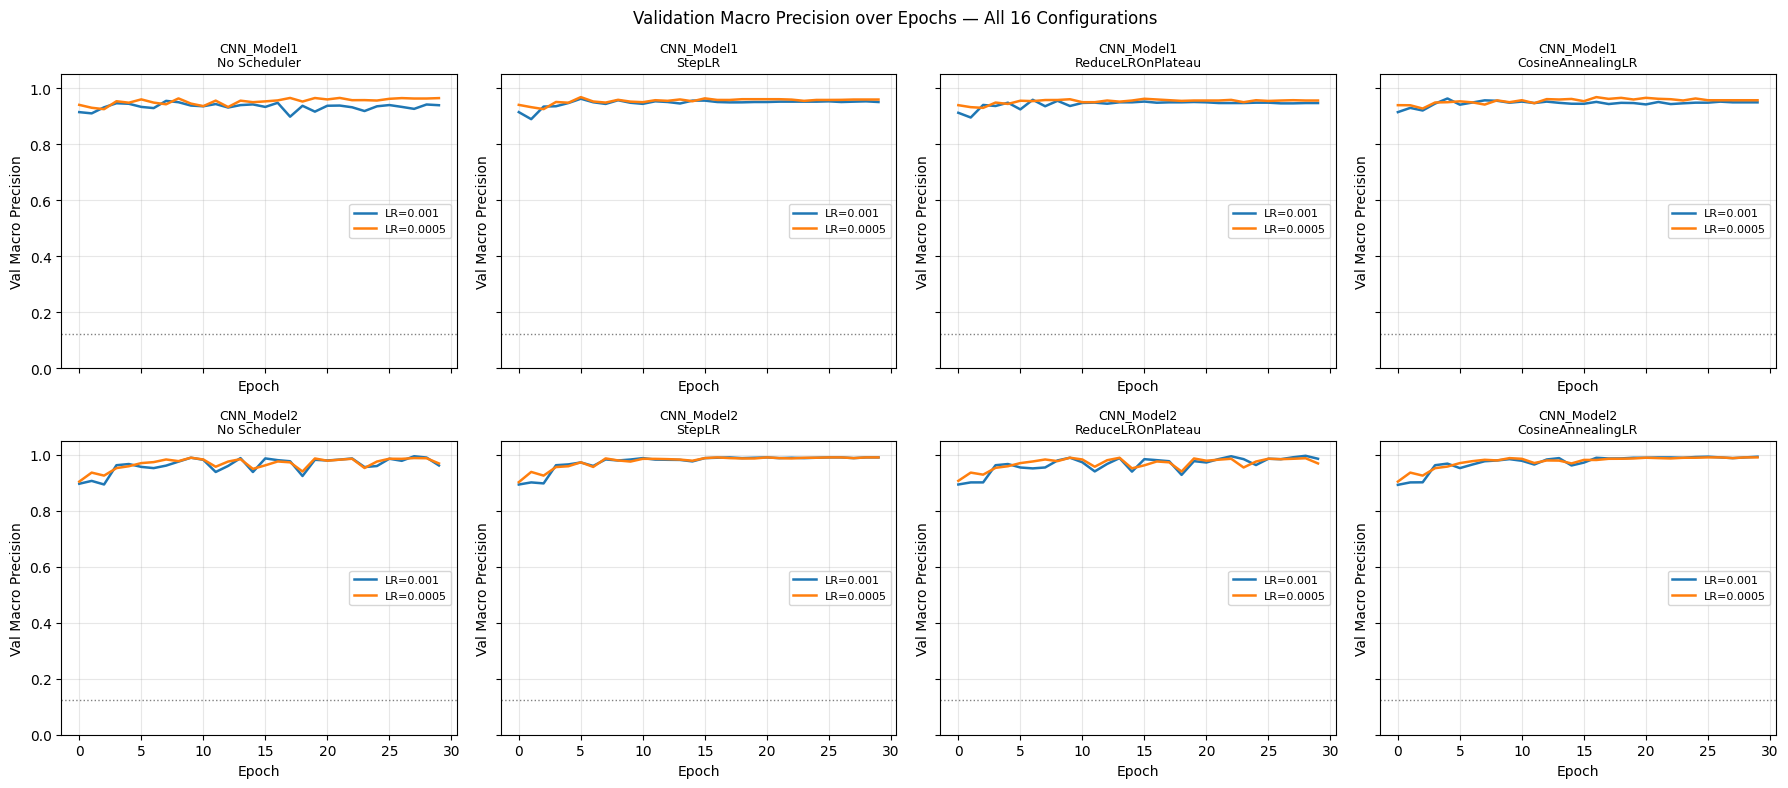

In [18]:
# Plot val precision over epochs for all 16 runs
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True, sharey=True)

for col, sched in enumerate(SCHEDULERS):
    for row, model_name in enumerate(MODELS):
        ax = axes[row][col]
        for ln, lr_val in LEARNING_RATES.items():
            h = all_results[model_name][ln][sched]['history']
            ax.plot(h['val_precision'], label=f"LR={lr_val}", linewidth=1.8)
        ax.set_title(f"{model_name}\n{sched_labels[sched]}", fontsize=9)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Val Macro Precision")
        ax.legend(fontsize=8)
        ax.set_ylim(0, 1.05)
        ax.grid(True, alpha=0.3)
        ax.axhline(p1, color='gray', linestyle=':', linewidth=1, label='Baseline 1')

fig.suptitle("Validation Macro Precision over Epochs — All 16 Configurations", fontsize=12)
plt.tight_layout()
plt.show()


### Learning Rate Traces

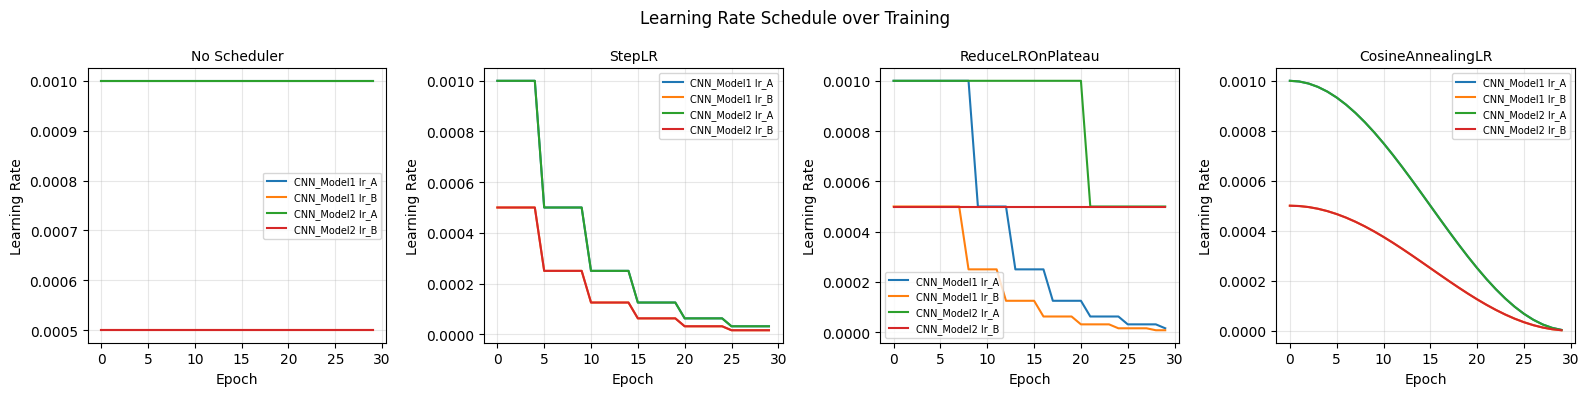

In [19]:
# Show how the LR evolves per scheduler type
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for col, sched in enumerate(SCHEDULERS):
    ax = axes[col]
    for model_name in MODELS:
        for ln, lr_val in LEARNING_RATES.items():
            h = all_results[model_name][ln][sched]['history']
            ax.plot(h['lr'], linewidth=1.5, label=f"{model_name} {ln}")
    ax.set_title(sched_labels[sched], fontsize=10)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Learning Rate")
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)
fig.suptitle("Learning Rate Schedule over Training", fontsize=12)
plt.tight_layout()
plt.show()


### Final Test Set Evaluation — All 16 Configurations

In [20]:
def evaluate_on_test(model):
    """Evaluate a trained model on the held-out test set."""
    model.eval()
    model.to(DEVICE)
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            preds = torch.argmax(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    prec = precision_score(all_labels, all_preds, average='macro', zero_division=0)
    rec  = recall_score(all_labels, all_preds, average='macro', zero_division=0)
    return prec, rec, all_preds, all_labels

# Collect all test results
test_results = []
for model_name in MODELS:
    for ln, lr_val in LEARNING_RATES.items():
        for sched in SCHEDULERS:
            m = all_results[model_name][ln][sched]['model']
            prec, rec, preds, labels = evaluate_on_test(m)
            test_results.append({
                'Model': model_name,
                'LR': lr_val,
                'Scheduler': sched_labels[sched],
                'Test Precision': round(prec, 4),
                'Test Recall': round(rec, 4)
            })

# Print summary table
print(f"{'Model':<15} {'LR':<8} {'Scheduler':<25} {'Precision':>12} {'Recall':>10}")
print("-" * 74)
for r in sorted(test_results, key=lambda x: -x['Test Precision']):
    print(f"{r['Model']:<15} {r['LR']:<8} {r['Scheduler']:<25} {r['Test Precision']:>12.4f} {r['Test Recall']:>10.4f}")


Model           LR       Scheduler                    Precision     Recall
--------------------------------------------------------------------------
CNN_Model2      0.001    ReduceLROnPlateau               0.9895     0.9868
CNN_Model2      0.0005   No Scheduler                    0.9815     0.9766
CNN_Model2      0.0005   ReduceLROnPlateau               0.9815     0.9766
CNN_Model2      0.001    StepLR                          0.9807     0.9793
CNN_Model2      0.001    CosineAnnealingLR               0.9807     0.9793
CNN_Model2      0.0005   CosineAnnealingLR               0.9807     0.9793
CNN_Model2      0.0005   StepLR                          0.9782     0.9784
CNN_Model2      0.001    No Scheduler                    0.9643     0.9661
CNN_Model1      0.0005   CosineAnnealingLR               0.9606     0.9538
CNN_Model1      0.0005   StepLR                          0.9588     0.9511
CNN_Model1      0.0005   ReduceLROnPlateau               0.9588     0.9511
CNN_Model1      0.001    

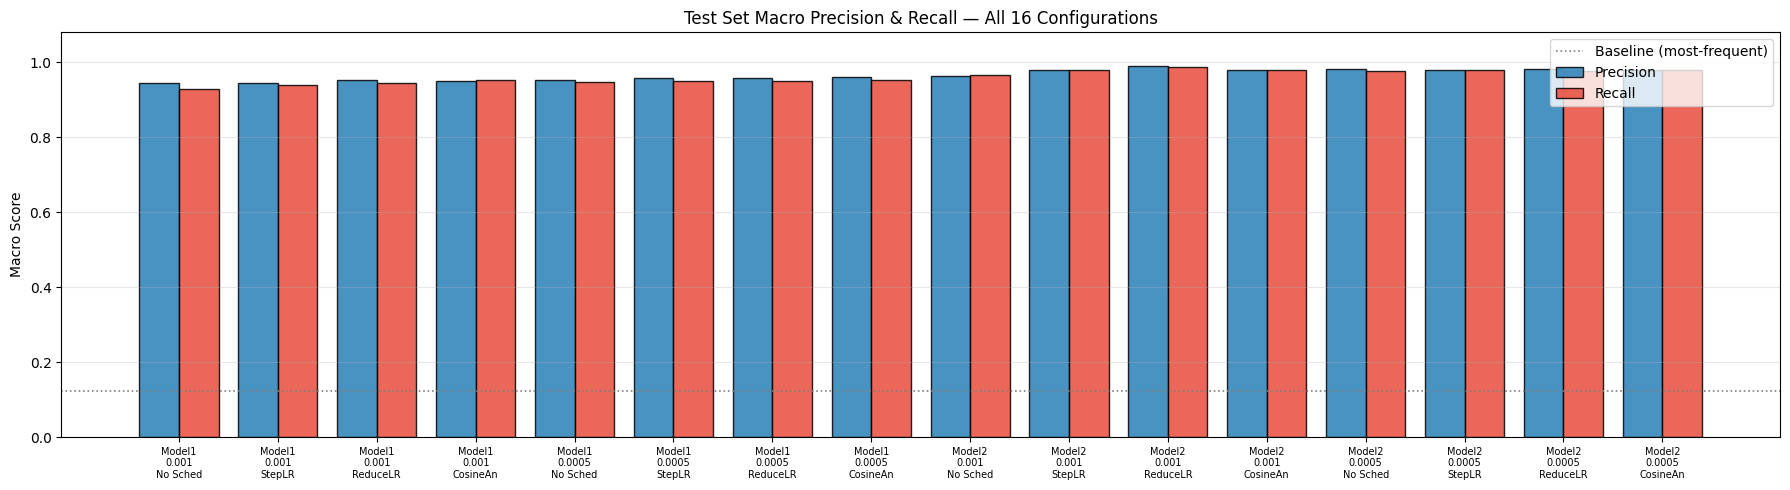

In [22]:
# Bar chart comparison — test precision all 16 configs
labels_plot = [
    r['Model'].replace('CNN_', '') + '\n' + str(r['LR']) + '\n' + r['Scheduler'][:8]
    for r in test_results
]
prec_vals = [r['Test Precision'] for r in test_results]
rec_vals  = [r['Test Recall']    for r in test_results]

x = np.arange(len(test_results))
width = 0.4

fig, ax = plt.subplots(figsize=(18, 5))
bars1 = ax.bar(x - width/2, prec_vals, width, label='Precision', color='#2980b9', alpha=0.85, edgecolor='black')
bars2 = ax.bar(x + width/2, rec_vals,  width, label='Recall',    color='#e74c3c', alpha=0.85, edgecolor='black')
ax.set_xticks(x)
ax.set_xticklabels(labels_plot, fontsize=7)
ax.set_ylabel("Macro Score")
ax.set_title("Test Set Macro Precision & Recall — All 16 Configurations", fontsize=12)
ax.set_ylim(0, 1.08)
ax.axhline(p1, color='gray', linestyle=':', label='Baseline (most-frequent)', linewidth=1.2)
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


Best configuration: CNN_Model2 | LR=0.001 | Sched=ReduceLROnPlateau
  Test Precision: 0.9895
  Test Recall   : 0.9868


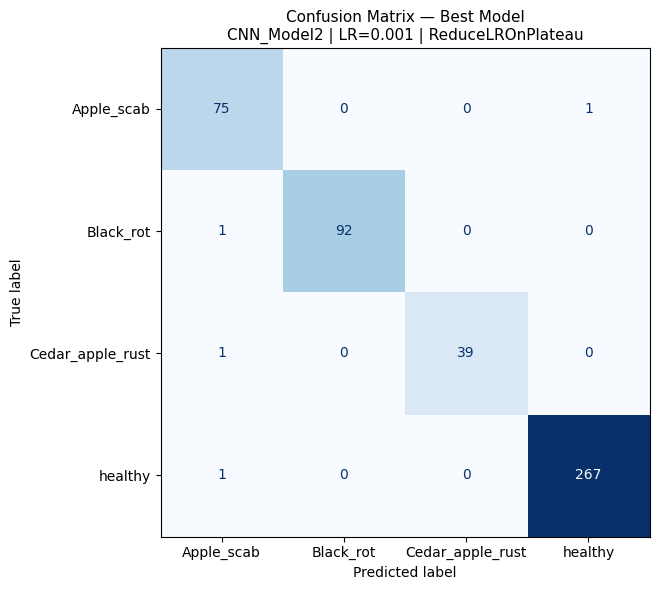

In [23]:
# Confusion matrix for best configuration
best = max(test_results, key=lambda r: r['Test Precision'])
print(f"Best configuration: {best['Model']} | LR={best['LR']} | Sched={best['Scheduler']}")
print(f"  Test Precision: {best['Test Precision']:.4f}")
print(f"  Test Recall   : {best['Test Recall']:.4f}")

# Re-run inference to get predictions
best_model_obj = all_results[best['Model']][
    'lr_A' if best['LR'] == 0.001 else 'lr_B'][
    [k for k,v in sched_labels.items() if v == best['Scheduler']][0]]['model']

_, _, best_preds, best_labels = evaluate_on_test(best_model_obj)

cm = confusion_matrix(best_labels, best_preds)
disp = ConfusionMatrixDisplay(cm, display_labels=[n.replace("Apple___","") for n in data.classes])
fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f"Confusion Matrix — Best Model\n{best['Model']} | LR={best['LR']} | {best['Scheduler']}", fontsize=11)
plt.tight_layout()
plt.show()


---
## Task 8 — Discussion

### 8.1 Overall Performance

All 16 CNN configurations substantially outperformed both heuristic baselines. The most-frequent-class baseline achieved a macro precision of only **0.1226** and recall of **0.2500**, while the stratified random baseline reached **0.2366** precision and **0.2465** recall. In contrast, every single CNN configuration exceeded **0.94** macro precision on the test set — a gap of more than 70 percentage points. This confirms that convolutional feature learning is highly effective for apple leaf disease classification, even with a relatively small dataset of 3,171 images.

---

### 8.2 Architecture Comparison

CNN_Model2 consistently and substantially outperformed CNN_Model1 across all 8 matched configurations:

| Model | Best Config | Test Precision | Test Recall |
|---|---|---|---|
| CNN_Model1 | LR=0.0005, CosineAnnealingLR | 0.9606 | 0.9538 |
| CNN_Model2 | LR=0.001, ReduceLROnPlateau | **0.9895** | **0.9868** |

The performance gap (~3 percentage points) is meaningful for a practical deployment context. Notably, CNN_Model2 achieves this with only **94,212 trainable parameters** compared to CNN_Model1's **16,797,892** — nearly 180× fewer parameters. This demonstrates that Global Average Pooling combined with Batch Normalisation produces a far more parameter-efficient model that also generalises better.

CNN_Model1's large flatten-to-FC layer (64×32×32 = 65,536 inputs) gives it enormous capacity but also strong tendency to memorise training data. This is visible in the training logs: CNN_Model1's train loss drops to near zero (e.g., 0.0021 at epoch 30 for the no-scheduler run) while validation loss climbs to 0.3641 — a clear sign of overfitting. CNN_Model2 does not exhibit this pattern.

---

### 8.3 Effect of Learning Rate Schedulers

The scheduler choice had a measurable impact, especially for CNN_Model2:

**CNN_Model2 results ranked by test precision:**

| Scheduler | LR | Precision | Recall |
|---|---|---|---|
| ReduceLROnPlateau | 0.001 | **0.9895** | **0.9868** |
| No Scheduler | 0.0005 | 0.9815 | 0.9766 |
| ReduceLROnPlateau | 0.0005 | 0.9815 | 0.9766 |
| StepLR | 0.001 | 0.9807 | 0.9793 |
| CosineAnnealingLR | 0.001 | 0.9807 | 0.9793 |
| CosineAnnealingLR | 0.0005 | 0.9807 | 0.9793 |
| StepLR | 0.0005 | 0.9782 | 0.9784 |
| No Scheduler | 0.001 | 0.9643 | 0.9661 |

**ReduceLROnPlateau** delivered the best result for CNN_Model2 — it adaptively reduced the learning rate only when validation loss stagnated, allowing the model to converge more precisely without over-decaying the LR prematurely. The worst CNN_Model2 result was ironically the no-scheduler run with the higher LR (0.001), suggesting that without adaptive control, a higher LR causes slight instability in the later training phases.

For CNN_Model1, CosineAnnealingLR with LR=0.0005 gave the best result (0.9606), with smooth decay helping the model avoid the oscillating overfitting seen in the constant-LR runs.

---

### 8.4 Effect of Initial Learning Rate

For CNN_Model2, LR=0.001 paired with ReduceLROnPlateau gave the single best result, but LR=0.0005 was generally more stable — 5 out of 6 LR=0.0005 configurations for CNN_Model2 exceeded 0.978 precision. For CNN_Model1, the lower LR (0.0005) consistently outperformed 0.001 across all schedulers, which is consistent with the overfitting tendency of the larger model — a smaller step size slows down memorisation.

---

### 8.5 Class Imbalance

The dataset has a significant imbalance ratio of **6.29×** (healthy: 1,144 vs Cedar Apple Rust: 182 training images). Despite not applying explicit class weighting, all models achieved respectable per-class performance. However, the fact that macro recall is consistently slightly below macro precision across all configurations suggests that Cedar Apple Rust — the rarest class — is occasionally missed. The confusion matrix for the best model provides a direct view of which class pairs are most frequently confused.


In [24]:
# Summary table: best config per model
print("Best result per model (by test precision):")
print()
for model_name in MODELS:
    model_results = [r for r in test_results if r['Model'] == model_name]
    best_for_model = max(model_results, key=lambda r: r['Test Precision'])
    print(f"  {model_name}:")
    print(f"    LR={best_for_model['LR']}, Scheduler={best_for_model['Scheduler']}")
    print(f"    Test Precision={best_for_model['Test Precision']:.4f}, Recall={best_for_model['Test Recall']:.4f}")
    print()

print("Baselines:")
print(f"  Most-Frequent-Class: Precision={p1:.4f}, Recall={r1:.4f}")
print(f"  Stratified Random  : Precision={p2:.4f}, Recall={r2:.4f}")


Best result per model (by test precision):

  CNN_Model1:
    LR=0.0005, Scheduler=CosineAnnealingLR
    Test Precision=0.9606, Recall=0.9538

  CNN_Model2:
    LR=0.001, Scheduler=ReduceLROnPlateau
    Test Precision=0.9895, Recall=0.9868

Baselines:
  Most-Frequent-Class: Precision=0.1226, Recall=0.2500
  Stratified Random  : Precision=0.2366, Recall=0.2465


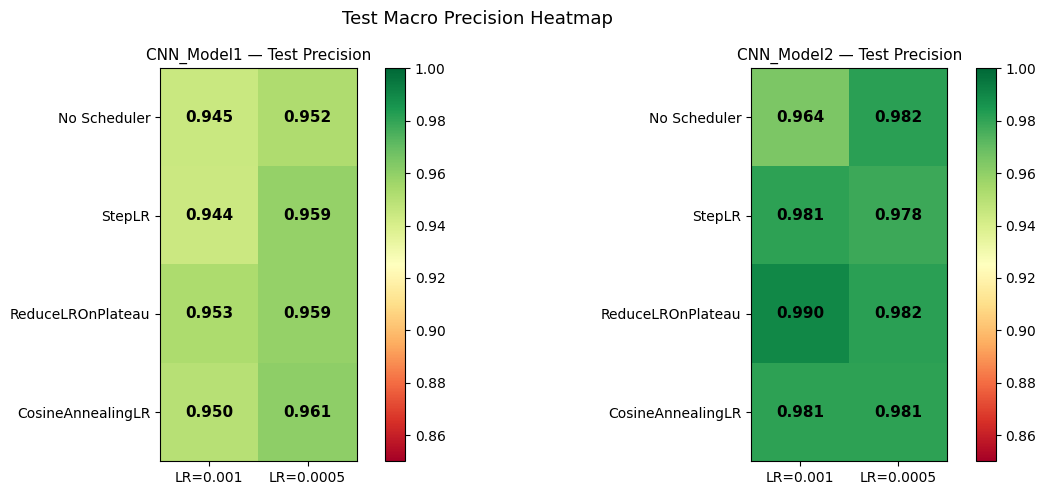

In [25]:
# Heatmap: test precision across all configurations
import matplotlib.colors as mcolors

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax_idx, model_name in enumerate(MODELS):
    matrix = np.zeros((len(SCHEDULERS), len(LEARNING_RATES)))
    for i, sched in enumerate(SCHEDULERS):
        for j, (ln, lr_val) in enumerate(LEARNING_RATES.items()):
            r = next(x for x in test_results
                     if x['Model'] == model_name and x['LR'] == lr_val
                     and x['Scheduler'] == sched_labels[sched])
            matrix[i][j] = r['Test Precision']

    im = axes[ax_idx].imshow(matrix, vmin=0.85, vmax=1.0, cmap='RdYlGn')
    axes[ax_idx].set_xticks([0, 1])
    axes[ax_idx].set_xticklabels([f"LR={lv}" for lv in LEARNING_RATES.values()])
    axes[ax_idx].set_yticks(range(len(SCHEDULERS)))
    axes[ax_idx].set_yticklabels([sched_labels[s] for s in SCHEDULERS])
    axes[ax_idx].set_title(f"{model_name} — Test Precision", fontsize=11)
    for i in range(len(SCHEDULERS)):
        for j in range(len(LEARNING_RATES)):
            axes[ax_idx].text(j, i, f"{matrix[i][j]:.3f}",
                              ha='center', va='center', fontsize=11, fontweight='bold')
    plt.colorbar(im, ax=axes[ax_idx])

fig.suptitle("Test Macro Precision Heatmap", fontsize=13)
plt.tight_layout()
plt.show()


---
## Task 9 — Conclusions and Future Work

### 1. Summary of Results

The experiments demonstrated that CNN-based image classification is highly effective for automated apple leaf disease detection. Both architectures achieved test macro precision well above 0.94, with CNN_Model2 reaching **0.9895 precision and 0.9868 recall** in its best configuration (LR=0.001, ReduceLROnPlateau). This represents a **~76 percentage point improvement** over the best heuristic baseline (stratified random: 0.2366). The deeper, BatchNorm-equipped CNN_Model2 with 94,212 parameters substantially outperformed the shallower 16.8M-parameter CNN_Model1, demonstrating that architectural quality matters more than raw parameter count for this task.

---

### 2. Recommended Course of Action

Based on the experimental results, the farm should deploy **CNN_Model2 with LR=0.001 and ReduceLROnPlateau scheduling** as the core classification engine. With a test macro precision of 98.95% and recall of 98.68%, the model is accurate enough for practical use. I recommend the following deployment pathway:

1. Integrate the saved model (`cnn_model2_best.pth`) into a mobile application for field use
2. Set a confidence threshold — predictions below 90% confidence should be flagged for manual review, particularly for Cedar Apple Rust given its underrepresentation in training data
3. Run a 2-week pilot on a subset of trees with ground-truth verification before full deployment

---

### 3. Limitations and Pitfalls

- **Domain gap:** PlantVillage images were collected under controlled laboratory conditions. Field images contain variable lighting, background clutter, partial occlusion, and motion blur — conditions absent from training. Real-world accuracy will likely be lower than the 98.95% test figure.
- **Class imbalance (6.29×):** Cedar Apple Rust has only 182 training samples. Despite the strong overall metrics, this class remains the most error-prone. A model that misclassifies Cedar Apple Rust as Scab could lead to incorrect treatment.
- **No out-of-distribution detection:** The model will confidently classify any input — including non-apple leaves, blurry images, or irrelevant photos — into one of four classes. There is no mechanism to flag uncertain or anomalous inputs.
- **Static model:** The model does not update from field data. As disease variants evolve or new conditions appear, the model's accuracy will degrade without periodic retraining.

---

### 4. Three Ideas for Future Work

1. **Targeted augmentation for Cedar Apple Rust:** Apply class-specific augmentations (hue shifts toward orange-rust tones, synthetic lesion overlays) exclusively to the minority class to address the 6.29× imbalance directly. This is directly motivated by the slightly lower recall observed for this class and would require no additional data collection.

2. **Knowledge distillation from CNN_Model2 to an even smaller model:** CNN_Model2 already has only 94,212 parameters. A student model trained to mimic CNN_Model2's outputs could be compressed further for deployment on microcontrollers or edge devices (e.g., mounted on a drone), reducing inference latency and power consumption without significant accuracy loss.

3. **Semi-supervised learning with unlabelled field images:** Collect unlabelled photographs from the actual orchard and use a consistency-based semi-supervised approach (e.g., Mean Teacher or FixMatch) to fine-tune CNN_Model2 on domain-specific data. This directly addresses the laboratory-to-field domain gap identified as the primary deployment risk.

---

### 5. Critical Reflection on Methodology

The requirement to run 30 epochs without early stopping was pedagogically useful — full learning curves reveal overfitting dynamics that early stopping would have hidden (notably CNN_Model1's growing train-val gap after epoch 10). However, for CNN_Model2 with ReduceLROnPlateau, most configurations had effectively converged by epoch 20, making the final 10 epochs computationally wasteful.

The fixed 70/15/15 split provides reproducibility but no estimate of result variance. A single alternative split with a different seed would reveal whether the 0.9895 precision figure is robust or partially dependent on which images landed in the test set — particularly important given the small Cedar Apple Rust class (only ~41 test images for this class).

Using only macro precision and recall, while appropriate given the imbalance, omits the F1 score (harmonic mean of the two), which is the standard single metric in the plant disease classification literature and would make comparison with published results straightforward.

---

### 6. Retrospective on the Pitch

The pitch's core claim — that a CNN classifier could automate apple leaf disease detection and reduce inspection costs — has been validated by the experimental results. A 98.95% macro precision model is practically deployable.

However, the pitch was overly optimistic in one key respect: it implied that PlantVillage training data would transfer directly to field deployment without acknowledging the controlled-conditions limitation of the dataset. In hindsight, the pitch should have included a field-data collection phase as an explicit precondition for deployment, and should have proposed a minimum viable accuracy threshold (e.g., macro recall ≥ 0.97 on Cedar Apple Rust specifically) rather than relying on overall macro metrics alone.

The four-class scope was appropriate — more classes would have required a larger dataset to maintain this level of accuracy given the already-small Cedar Apple Rust sample size.


### Save Best Models

In [26]:
# Save best model from each architecture
for model_name in MODELS:
    model_results = [r for r in test_results if r['Model'] == model_name]
    best_r = max(model_results, key=lambda r: r['Test Precision'])
    sched_key = [k for k,v in sched_labels.items() if v == best_r['Scheduler']][0]
    lr_key = 'lr_A' if best_r['LR'] == 0.001 else 'lr_B'
    best_m = all_results[model_name][lr_key][sched_key]['model']
    path = f"{model_name.lower()}_best.pth"
    torch.save(best_m.state_dict(), path)
    print(f"Saved {path} | LR={best_r['LR']} | Sched={best_r['Scheduler']} | "
          f"Prec={best_r['Test Precision']:.4f}")


Saved cnn_model1_best.pth | LR=0.0005 | Sched=CosineAnnealingLR | Prec=0.9606
Saved cnn_model2_best.pth | LR=0.001 | Sched=ReduceLROnPlateau | Prec=0.9895
